# Распознавание режимов работы печи

In [1]:
import numpy as np

from fcl.serializator import to_fcl
import copy

from fcl.translator import Translator
from builder import Builder
from fcl.parser import FCLParser
from kernel.blocks import FunctionBlockBase, ClassifierFunctionalBlock

filename = "samples/oven/oven-gauss.fcl"
parser = FCLParser(filename)
builder = Builder()
translator = Translator().translate(parser, builder)

mamdani_block = copy.deepcopy(builder.func_block)
print(to_fcl(mamdani_block))

FUNCTION_BLOCK Распознавание_процессов_в_печи

VAR_INPUT
	i_0 : LING;
	i_1 : LING;
	i_2 : LING;
	i_3 : LING;
	i_4 : LING;
	i_5 : LING;
	i_6 : LING;
	i_7 : LING;
	i_8 : LING;
	i_9 : LING;
	i_10 : LING;
	no_0 : LING;
	no_1 : LING;
	no_2 : LING;
	no_3 : LING;
	no_4 : LING;
	no_5 : LING;
	no_6 : LING;
	no_7 : LING;
	no_8 : LING;
	no_9 : LING;
	no_10 : LING;
END_VAR

VAR_OUTPUT
	Обр_колец_в_зоне_спек : LING;
	Обр_колец_перед_з_спек : LING;
	Охл_зоны_спекания : LING;
	Нагрев_зоны_спекания : LING;
END_VAR
FUZZIFY i_0
    METHOD: GAUSS;
    UNITS: "усл. амп.";
	RANGE := (0.3 .. 1.7)
	TERM HN := GAUSS(0.3, 0.3) LEARN;
	TERM N := GAUSS(0.85, 0.1) LEARN;
	TERM LN := GAUSS(0.95, 0.05) LEARN;
	TERM Z := GAUSS(1.0, 0.025) LEARN;
	TERM LP := GAUSS(1.05, 0.05) LEARN;
	TERM P := GAUSS(1.15, 0.1) LEARN;
	TERM HP := GAUSS(1.7, 0.3) LEARN;
END_FUZZIFY    
    FUZZIFY i_1
    METHOD: GAUSS;
    UNITS: "усл. амп.";
	RANGE := (0.3 .. 1.7)
	TERM HN := GAUSS(0.3, 0.3) LEARN;
	TERM N := GAUSS(0.85, 0.1) LEARN;


### Термы входных переменных

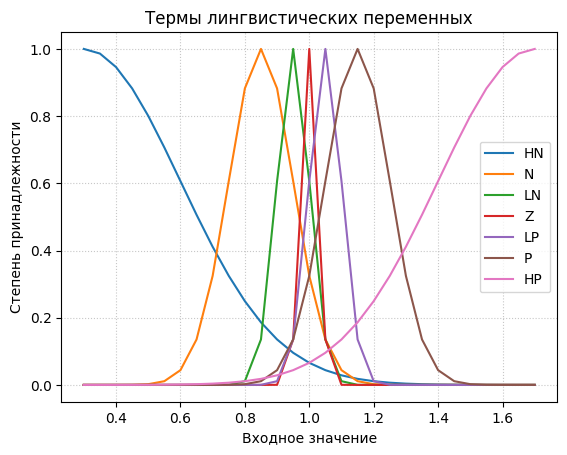

In [2]:
import matplotlib.pyplot as plt

terms = mamdani_block.inputs[0].terms
for term in terms:
    x, y = [], []
    for node in term.func.nodes:
        x.append(node.x)
        y.append(node.dom)

    plt.plot(x, y, label=term.name)

plt.xlabel('Входное значение')
plt.ylabel('Степень принадлежности')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.title("Термы лингвистических переменных")
plt.show()

### Входные данные

In [5]:
import pandas as pd

df = pd.read_csv('samples/oven/oven-test.csv')
x, y = df.iloc[:, :22], df.iloc[:, 22:]
df

,i_0,i_1,i_2,i_3,i_4,i_5,i_6,i_7,i_8,i_9,...,n_5,n_6,n_7,n_8,n_9,n_10,Обр_колец_в_зоне_спек,Обр_колец_перед_з_спек,Охл_зоны_спекания,Нагрев_зоны_спекания
0,1.000,0.990,0.974,0.969,0.960,1.000,1.116,0.986,0.893,0.831,...,0.863,0.835,0.840,0.821,0.878,0.863,1,0,0,0
1,0.995,0.972,0.934,0.924,0.986,1.082,1.043,0.853,0.778,0.796,...,0.859,0.905,0.959,1.006,1.052,1.070,1,0,0,0
2,1.000,0.975,0.920,1.012,1.177,1.249,1.037,0.920,0.752,0.775,...,0.874,0.843,0.843,0.863,0.869,0.890,1,0,0,0
3,0.995,0.987,0.972,0.962,0.972,1.095,1.176,1.138,0.916,0.854,...,0.607,0.501,0.464,0.429,0.411,0.519,1,0,0,0
4,1.000,0.987,0.946,1.128,1.089,1.048,0.982,0.954,0.903,0.867,...,0.763,0.731,0.657,0.624,0.613,0.624,1,0,0,0
5,1.000,0.976,0.915,0.882,0.829,0.945,1.229,1.376,1.222,1.073,...,0.667,0.500,0.416,0.464,0.428,0.434,1,0,0,0
6,1.000,0.988,0.936,0.866,0.970,1.146,1.240,1.033,0.906,0.644,...,0.893,0.823,0.756,0.756,0.710,0.794,1,0,0,0
7,1.000,0.995,0.977,0.966,0.948,0.995,1.116,0.985,0.863,0.858,...,0.775,0.703,0.616,0.746,0.841,0.864,1,0,0,0
8,1.000,0.831,0.813,1.108,1.159,1.132,1.083,1.054,1.029,1.013,...,0.810,0.862,0.878,0.870,0.823,0.713,1,0,0,0
9,1.015,1.035,1.053,1.047,1.190,1.267,1.237,1.193,1.163,1.116,...,0.969,0.982,0.960,0.969,0.955,0.928,0,1,0,0


In [3]:
import time
from kernel.blocks import FunctionBlockBase

def test_block(b: FunctionBlockBase):
    all_cases = np.zeros(4)
    success_cases = np.zeros(4)

    start = time.perf_counter()
    for x_i, y_i in zip(x.values, y.values):
        test = np.argmax(y_i)
        all_cases[test] += 1
        out = b.crisp_evaluate_to_crisp(x_i)
        res = np.argmax(out)
        if res == test:
            success_cases[test] += 1
    
    delta = time.perf_counter() - start
    return success_cases / all_cases, delta / len(x.values)

In [6]:
mamdani_percents, mamdani_time = test_block(mamdani_block)
cp_block = ClassifierFunctionalBlock.create_from_func_block(mamdani_block)
cp_percents, cp_time  = test_block(cp_block)

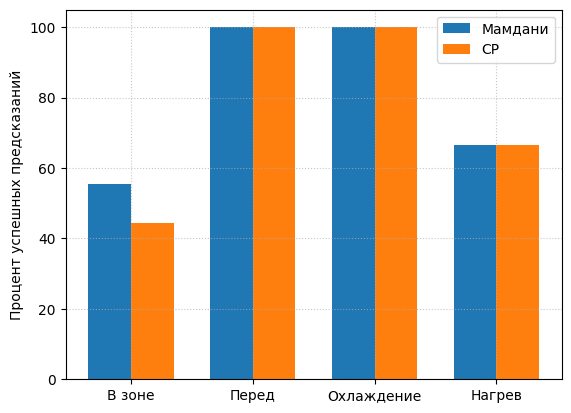

In [7]:
categories = ["В зоне","Перед","Охлаждение","Нагрев"]

v = np.arange(len(categories))  # позиции категорий
width = 0.35                    # ширина столбца

fig, ax = plt.subplots()

ax.bar(v - width/2, mamdani_percents * 100, width, label='Мамдани')
ax.bar(v + width/2, cp_percents * 100, width, label='CP')


ax.set_ylabel('Процент успешных предсказаний')
ax.set_xticks(v)
ax.set_xticklabels(categories)
ax.legend()
ax.grid(True, linestyle=':', alpha=0.7)
plt.show()

In [8]:
print(f'Среднее время вывода Мамдани: {mamdani_time:.6f} сек.')
print(f'Среднее время вывода CP: {cp_time:.6f} сек.')

Среднее время вывода Мамдани: 4.100709 сек.
Среднее время вывода CP: 0.081802 сек.
